### Ändra arbetskatalog

In [1]:
import os

# Byter arbetskatalog från notebooks till projektroten om det behövs
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar att Python arbetar från rätt katalog
print("Arbetskatalog:", os.getcwd())

Arbetskatalog: c:\Users\josef\Desktop\data-science-group-project


### Importera paket och egna moduler

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Projektets egna moduler
from src.data_split import load_cleaned_data, get_splits
from src.preprocessing import split_features_target, build_preprocessor
from src.random_forest import train_random_forest, get_feature_importances
from src.prediction import predict_probabilities
from src.evaluation import evaluate_top_share, plot_roc_curve, plot_confusion_matrix
from src.experiment_logger import log_experiment, save_plot, get_leaderboard

### Ladda data och kronologiska splits

In [3]:
# Läser in städad data från data/processed/
df = load_cleaned_data()

# Hämtar de kronologiska uppdelningarna
splits = get_splits(df)
train = splits["train_val"]
val = splits["val"]

print("Träningsdata (train_val):", train.shape)
print("Valideringsdata (val):", val.shape)

# Kontroll av att den aktuella datan används
assert len(train) == 40414, "Fel antal rader i train_val. Kör python -m src.data_cleaning"

2026-10-22 06:58:12 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
2026-10-22 06:58:13 [INFO] src.data_cleaning: Validerar städad data med Pandera...
2026-10-22 06:58:13 [INFO] src.data_cleaning: Datavalidering godkänd utan anmärkningar.
2026-10-22 06:58:13 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-22 06:58:13 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Träningsdata (train_val): (40414, 34)
Valideringsdata (val): (11643, 34)


### Huvudmodell (UTAN `deposit_type`)

In [4]:
# 1. Separera X och y för träning och validering
X_train_full, y_train = split_features_target(train, include_deposit_type=False)
X_val_full, y_val = split_features_target(val, include_deposit_type=False)

# 2. Skapa preprocessor och transformera
# Vi kör fit_transform på träning och bara transform på validering för att undvika dataläckage
preprocessor_full = build_preprocessor(include_deposit_type=False)
X_train_full_p = preprocessor_full.fit_transform(X_train_full)
X_val_full_p = preprocessor_full.transform(X_val_full)

print("Huvudmodell - Train:", X_train_full_p.shape)
print("Huvudmodell - Val:", X_val_full_p.shape)

Huvudmodell - Train: (40414, 114)
Huvudmodell - Val: (11643, 114)


### Hyperoptimering: `max_depth` och `min_samples_leaf`

OBS! Vi använder inte standard k-fold CV för att inte bryta den kronologiska tidsuppdelningen.

Vi tränar strikt på `train_val` och utvärderar på `val`.

In [5]:
depth_candidates = [10, 15, 20]
leaf_candidates = [1, 2, 5, 10, 20]

tuning_results = []

print(f"Startar sökning över {len(depth_candidates) * len(leaf_candidates)} kombinationer...\n")

for depth in depth_candidates:
  for leaf in leaf_candidates:
    # 1. Träna modellen på train_val
    model = train_random_forest(
        X_train_full_p,
        y_train,
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1,
    )

    # 2. Beräkna predicerade sannolikheter på valideringsdatan (val)
    probas = predict_probabilities(model, X_val_full_p)

    # 3. Utvärdera mätvärden vid de 20 % högst rankade bokningarna
    metrics = evaluate_top_share(y_val, probas, share=0.20)

    tuning_results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "precision_at_20": metrics["precision"],
        "recall_at_20": metrics["recall"],
        "f1_score": metrics["f1_score"],
        "korrekt_flaggade": metrics["korrekt_flaggade"],
    })
    print(
        f"Klar: max_depth={depth:<2} | min_samples_leaf={leaf:<2} -> "
        f"Precision@20: {metrics['precision']:.4f} | Recall@20: {metrics['recall']:.4f} "
        f"({metrics['korrekt_flaggade']} träffar)"
    )

# Sammanställ alla resultat i en DataFrame
df_tuning = pd.DataFrame(tuning_results)

# Sortera efter bäst precision (eller flest korrekt flaggade avbokningar)
df_tuning_sorted = df_tuning.sort_values(
    by=["korrekt_flaggade", "precision_at_20"], ascending=False
).reset_index(drop=True)

print("\n--- Resultat (Topp 5 kombinationer) ---")
display(df_tuning_sorted.head())

Startar sökning över 15 kombinationer...

Klar: max_depth=10 | min_samples_leaf=1  -> Precision@20: 0.5921 | Recall@20: 0.3358 (1379 träffar)
Klar: max_depth=10 | min_samples_leaf=2  -> Precision@20: 0.6363 | Recall@20: 0.3608 (1482 träffar)
Klar: max_depth=10 | min_samples_leaf=5  -> Precision@20: 0.5985 | Recall@20: 0.3394 (1394 träffar)
Klar: max_depth=10 | min_samples_leaf=10 -> Precision@20: 0.6282 | Recall@20: 0.3562 (1463 träffar)
Klar: max_depth=10 | min_samples_leaf=20 -> Precision@20: 0.6174 | Recall@20: 0.3501 (1438 träffar)
Klar: max_depth=15 | min_samples_leaf=1  -> Precision@20: 0.6385 | Recall@20: 0.3621 (1487 träffar)
Klar: max_depth=15 | min_samples_leaf=2  -> Precision@20: 0.6415 | Recall@20: 0.3638 (1494 träffar)
Klar: max_depth=15 | min_samples_leaf=5  -> Precision@20: 0.6488 | Recall@20: 0.3679 (1511 träffar)
Klar: max_depth=15 | min_samples_leaf=10 -> Precision@20: 0.6475 | Recall@20: 0.3672 (1508 träffar)
Klar: max_depth=15 | min_samples_leaf=20 -> Precision@20: 

,max_depth,min_samples_leaf,precision_at_20,recall_at_20,f1_score,korrekt_flaggade
0,20,5,0.650494,0.368882,0.470789,1515
1,15,20,0.649635,0.368395,0.470168,1513
2,15,5,0.648776,0.367908,0.469546,1511
3,15,10,0.647488,0.367178,0.468614,1508
4,20,10,0.646629,0.366691,0.467993,1506


### Visualisering av resultaten

min_samples_leaf,1,2,5,10,20
max_depth,,,,,
10,0.5921,0.6363,0.5985,0.6282,0.6174
15,0.6385,0.6415,0.6488,0.6475,0.6496
20,0.5861,0.6286,0.6505,0.6466,0.6376


2026-10-22 06:58:32 [INFO] src.experiment_logger: Figur sparad: outputs\figures\rf_hyperparameter_tuning_heatmap.png


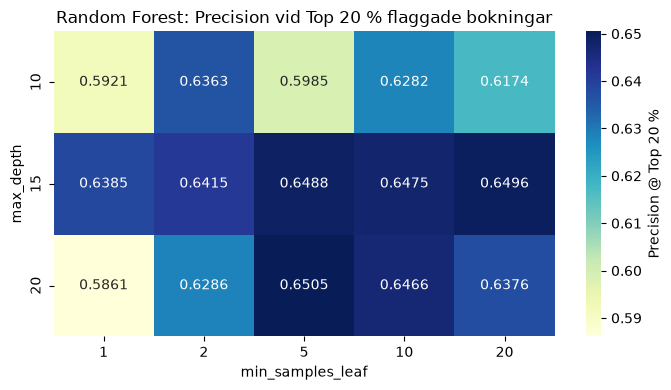

In [6]:
# Skapa en pivot-tabell för en tydlig översikt
pivot_precision = df_tuning.pivot(
    index="max_depth", columns="min_samples_leaf", values="precision_at_20"
)

display(pivot_precision.round(4))

plt.figure(figsize=(7, 4))
sns.heatmap(
    pivot_precision, 
    annot=True, 
    fmt=".4f", 
    cmap="YlGnBu", 
    cbar_kws={'label': 'Precision @ Top 20 %'}
)
plt.title("Random Forest: Precision vid Top 20 % flaggade bokningar")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.tight_layout()

# Spara figuren till outputs/figures/
save_plot("rf_hyperparameter_tuning_heatmap.png")

plt.show()

### Slutsats från hyperparameteroptimeringen

Värmekartan visar precisionen vid topp 20 % flaggade bokningar på valideringsdatan (`val`) för olika kombinationer av `max_depth` och `min_samples_leaf`:

* **Högsta värde:** `max_depth = 20` och `min_samples_leaf = 5` gav högst precision (**0.6505**), men flera kombinationer ligger mycket nära. `max_depth = 15` med `min_samples_leaf = 20` gav 0.6496, en skillnad på 2–3 korrekt flaggade bokningar.
* **Stabilitet:** `max_depth = 15` ger nästan samma precision oavsett lövstorlek (0.6385–0.6496), medan `max_depth = 10` och `max_depth = 20` varierar mer.
* **Överanpassning:** Med `max_depth = 20` och `min_samples_leaf = 1` sjunker precisionen till **0.5861**. När träden får bli djupa utan krav på minsta lövstorlek anpassar sig modellen för mycket till träningsdatan.

**Beslut:** Huvudmodellen använder `max_depth = 15` och `min_samples_leaf = 10`. Kombinationen ligger nära det högsta värdet och är mindre känslig för exakt vilka inställningar som väljs. Skillnaderna i toppen är så små att de kan bero på slumpen.

### Träna huvudmodellen och prediktera sannolikheter

In [7]:
# Träna huvudmodellen med de valda inställningarna (se hyperparameteroptimeringen).
# min_samples_leaf=5 begränsar överanpassning när träden får bli djupa.
rf_full = train_random_forest(
    X_train_full_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

# Beräkna sannolikheten för avbokning (klass 1)
probas_full = predict_probabilities(rf_full, X_val_full_p)
print("Första 10 sannolikheterna (huvudmodell):", probas_full[:10])

Första 10 sannolikheterna (huvudmodell): [0.09982009 0.10394144 0.1494578  0.1371324  0.07069592 0.06112228
 0.14645169 0.13294813 0.12247517 0.07618919]


### Utvärdera top 20 % - Huvudmodellen (utan `deposit_type`)

In [8]:
# 1. Beräkna mätvärden för de 20 % bokningarna med högst riskpoäng
metrics_full = evaluate_top_share(y_val, probas_full, share=0.20)

print("Top 20 %-resultat (utan deposit_type):")
for k, v in metrics_full.items():
    print(f"  {k}: {v}")

Top 20 %-resultat (utan deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1508
  precision: 0.6474881923572349
  recall: 0.36717798879961044
  f1_score: 0.46861404599129897
  pr_auc: 0.5913229899962382


## Utvärdering av bokningar med och utan registrerade ändringar

För att undersöka hur modellen presterar för olika typer av bokningar
delas valideringsdatan upp i två grupper baserat på `booking_changes`:

- Bokningar utan registrerade ändringar (`booking_changes == 0`)
- Bokningar med registrerade ändringar (`booking_changes > 0`)

De 20 % av bokningarna med högst risk flaggas i hela valideringsdatan.
Därefter beräknas precision och recall separat för respektive grupp.

In [9]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score
from src.evaluation import flag_top_share

# Flagga de 20 % med högst risk i hela valideringsdatan
y_pred_rf = flag_top_share(probas_full, share=0.20)

# Faktiska avbokningar och prediktioner
y_true = pd.Series(y_val, index=val.index)
y_pred_rf = pd.Series(
    y_pred_rf, index=val.index
)

# Dela upp efter registrerade ändringar
groups = {
    "Utan ändringar": val["booking_changes"] == 0,
    "Med ändringar": val["booking_changes"] > 0
}

results_by_group = []

for group_name, mask in groups.items():
    group_true = y_true.loc[mask]
    group_pred = y_pred_rf.loc[mask]

    precision = precision_score(
        group_true, group_pred, zero_division=0
    )

    recall = recall_score(
        group_true, group_pred, zero_division=0
    )

    results_by_group.append({
        "Modell": "Random Forest",
        "Grupp": group_name,
        "Antal bokningar": len(group_true),
        "Antal flaggade": int(group_pred.sum()),
        "Precision": precision,
        "Recall": recall
    })

rf_group_results = pd.DataFrame(results_by_group)

display(
    rf_group_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,Modell,Grupp,Antal bokningar,Antal flaggade,Precision,Recall
0,Random Forest,Utan ändringar,9790,1997,67.60%,36.39%
1,Random Forest,Med ändringar,1853,332,47.59%,39.80%


### Random Forest – Bokningar med och utan registrerade ändringar

Random Forest utvärderades genom att flagga de 20 % av bokningarna med högst förutsagd avbokningsrisk i hela valideringsdatan. Resultaten delades därefter upp efter `booking_changes`.

För bokningar utan registrerade ändringar var precision **67,60 %** och recall **36,39 %**. För bokningar med registrerade ändringar var precision **47,59 %** och recall **39,80 %**.

Random Forest hade högst precision och recall av de tre modellerna i båda grupperna. Precisionen var högre för bokningar utan ändringar, medan recall var något högre för bokningar med ändringar.

Skillnaderna visar att modellernas resultat varierar mellan grupperna. Jämförelsen kan dock inte avgöra om dataläckage förekommer eftersom de ursprungliga värdena före eventuella ändringar saknas.

### Jämförelsemodell (MED `deposit_type`)

In [10]:
# 1. Separera X och y med deposit_type
X_train_dep, y_train = split_features_target(train, include_deposit_type=True)
X_val_dep, y_val = split_features_target(val, include_deposit_type=True)

# 2. Skapa ny preprocessor med deposit_type och transformera
preprocessor_dep = build_preprocessor(include_deposit_type=True)
X_train_dep_p = preprocessor_dep.fit_transform(X_train_dep)
X_val_dep_p = preprocessor_dep.transform(X_val_dep)

print("Jämförelsemodell - Train:", X_train_dep_p.shape)
print("Jämförelsemodell - Val:", X_val_dep_p.shape)

Jämförelsemodell - Train: (40414, 117)
Jämförelsemodell - Val: (11643, 117)


### Träna jämförelsemodellen och prediktera sannolikheter

In [11]:
# Träna modellen med deposit_type
rf_dep = train_random_forest(
    X_train_dep_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

# Beräkna sannolikheter på valideringsdatan
probas_dep = predict_probabilities(rf_dep, X_val_dep_p)
print("Första 10 sannolikheterna (med deposit_type):", probas_dep[:10])

Första 10 sannolikheterna (med deposit_type): [0.0965661  0.10110887 0.14144268 0.14186386 0.06921603 0.06214599
 0.14951826 0.12732103 0.12272661 0.0711913 ]


### Utvärdera top 20 % och logga jämförelsemodellen

In [12]:
# 1. Beräkna mätvärden för Top 20 %
metrics_dep = evaluate_top_share(y_val, probas_dep, share=0.20)

print("Top 20 %-resultat (med deposit_type):")
for k, v in metrics_dep.items():
    print(f"  {k}: {v}")

Top 20 %-resultat (med deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1566
  precision: 0.6723915843709747
  recall: 0.38130021913805695
  f1_score: 0.48663766314481044
  pr_auc: 0.6288719819044272


### Jämförelse, visualisering och feature importance

#### Rita och spara gemensam ROC-kurva

2026-10-22 06:59:07 [INFO] src.experiment_logger: Figur sparad: outputs\figures\rf_val_deposit_comparison_roc.png


WindowsPath('outputs/figures/rf_val_deposit_comparison_roc.png')

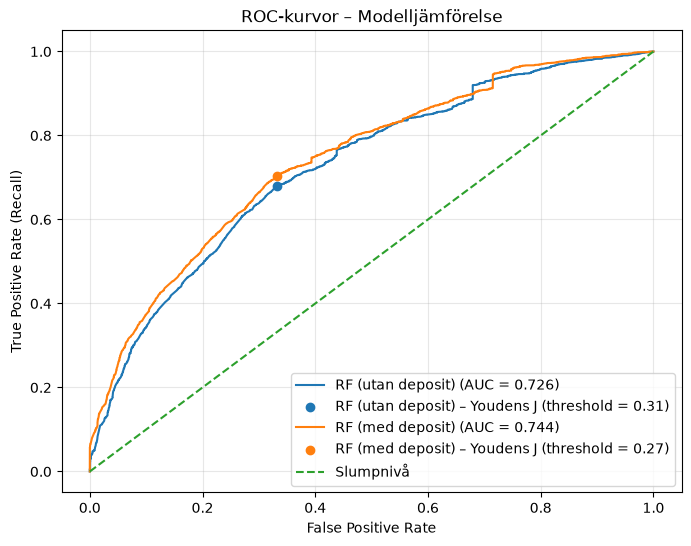

In [13]:
# plot_roc_curve tar en dictionary med modellnamn och tillhörande sannolikheter
roc_results = plot_roc_curve(
    y_val,
    {
        "RF (utan deposit)": probas_full,
        "RF (med deposit)": probas_dep
    }
)

# Spara figuren högupplöst till mappen outputs/figures/
save_plot("rf_val_deposit_comparison_roc.png")

### Jämförelse med och utan `deposit_type`

In [14]:
summary = pd.DataFrame([
    {"Variant": "Utan deposit_type", **metrics_full},
    {"Variant": "Med deposit_type", **metrics_dep},
]).set_index("Variant")[["antal_bokningar", "antal_flaggade", "korrekt_flaggade",
                         "precision", "recall", "pr_auc"]]
summary.insert(0, "antal_traning", len(y_train))
display(summary.round(4))

,antal_traning,antal_bokningar,antal_flaggade,korrekt_flaggade,precision,recall,pr_auc
Variant,,,,,,,
Utan deposit_type,40414,11643,2329,1508,0.6475,0.3672,0.5913
Med deposit_type,40414,11643,2329,1566,0.6724,0.3813,0.6289


### Sammanfattning: med och utan `deposit_type`

Båda varianterna tränades på `train_val` (40 414 bokningar) med samma inställningar (n_estimators=100, max_depth=15, min_samples_leaf=10) och utvärderades på valideringsdatan (11 643 bokningar). Båda flaggade 2 329 bokningar, alltså 20 %.

| Variant | Korrekt flaggade | Precision | Recall | PR-AUC |
|---|---|---|---|---|
| Utan `deposit_type` (huvudmodell) | 1 508 | 64,75 % | 36,72 % | 0,5913 |
| Med `deposit_type` | 1 566 | 67,24 % | 38,13 % | 0,6289 |

Modellen **med** `deposit_type` uppnår högre precision och recall på valideringsdatan (58 fler korrekt flaggade avbokningar vid 20 % flaggning).

Trots den högre prestandan väljs varianten **utan `deposit_type`** som projektets huvudmodell. `deposit_type` bedöms innebära en påtaglig risk för målläckage/tidsläckage, eftersom villkoren för deposition (särskilt Non Refund) ofta registreras eller ändras i nära anslutning till avbokningen snarare än vid den ursprungliga bokningstidpunkten. Huvudmodellen prioriterar därmed robusthet och tillförlitlighet i skarp drift.

#### Feature Importances (vilka variabler väger tyngst?)

In [15]:
# Hämta namnen på alla transformerade kolumner från preprocessorn
feature_names = preprocessor_full.get_feature_names_out()

# Hämta och sortera feature importances fallande
df_importance = get_feature_importances(rf_full, feature_names)

print("Topp 15 viktigaste features i Random Forest:")
display(df_importance.head(15))

Topp 15 viktigaste features i Random Forest:


,feature,importance
0,num__previous_cancellations,0.195806
1,num__lead_time,0.172287
2,cat__market_segment_Groups,0.077406
3,cat__customer_type_Transient,0.076735
4,cat__customer_type_Transient-Party,0.071011
5,cat__hotel_City Hotel,0.022093
6,cat__market_segment_Direct,0.021782
7,cat__hotel_Resort Hotel,0.019955
8,cat__market_segment_Offline TA/TO,0.019224
9,cat__market_segment_Online TA,0.018413


## Jämförelsemodell med misstänkta läckagevariabler

In [16]:
# Förbered data med misstänkta läckagevariabler
X_train_leak, y_train_leak = split_features_target(
    train,
    include_deposit_type=False,
    include_suspected_leakage=True
)

X_val_leak, y_val_leak = split_features_target(
    val,
    include_deposit_type=False,
    include_suspected_leakage=True
)

preprocessor_leak = build_preprocessor(
    include_deposit_type=False,
    include_suspected_leakage=True
)

X_train_leak_p = preprocessor_leak.fit_transform(X_train_leak)
X_val_leak_p = preprocessor_leak.transform(X_val_leak)

print("Jämförelsemodell - Train:", X_train_leak_p.shape)
print("Jämförelsemodell - Val:", X_val_leak_p.shape)

Jämförelsemodell - Train: (40414, 159)
Jämförelsemodell - Val: (11643, 159)


In [17]:
# Samma hyperparametrar som huvudmodellen
rf_leak = train_random_forest(
    X_train_leak_p,
    y_train_leak,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

probas_leak = predict_probabilities(
    rf_leak,
    X_val_leak_p
)

print("Första 10 sannolikheterna:", probas_leak[:10])

Första 10 sannolikheterna: [0.05500687 0.1731176  0.1568187  0.2248094  0.12890262 0.11652777
 0.21637566 0.19779292 0.12945055 0.10061966]


In [18]:
# Utvärdera jämförelsemodellen
metrics_leak = evaluate_top_share(
    y_val_leak,
    probas_leak,
    share=0.20
)

# Jämför med huvudmodellen
comparison = pd.DataFrame([
    {
        "Modell": "Huvudmodell",
        "Precision": metrics_full["precision"],
        "Recall": metrics_full["recall"],
        "PR-AUC": metrics_full["pr_auc"]
    },
    {
        "Modell": "Med misstänkta läckagevariabler",
        "Precision": metrics_leak["precision"],
        "Recall": metrics_leak["recall"],
        "PR-AUC": metrics_leak["pr_auc"]
    }
])

display(
    comparison.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "PR-AUC": "{:.4f}"
    })
)

,Modell,Precision,Recall,PR-AUC
0,Huvudmodell,64.75%,36.72%,0.5913
1,Med misstänkta läckagevariabler,69.94%,39.66%,0.6632


### Resultat och slutsats: Misstänkta läckagevariabler

För att undersöka hur de misstänkta läckagevariablerna påverkar modellens resultat tränades en extra Random Forest-modell med samma träningsdata, valideringsdata och hyperparametrar som huvudmodellen. Den enda skillnaden var att jämförelsemodellen även inkluderade variablerna `adults`, `children`, `babies`, `stays_in_weekend_nights`, `stays_in_week_nights`, `meal` och `country`.

| Modell | Precision@20% | Recall@20% | PR-AUC |
|---|---|---|---|
| Huvudmodell | 64,75 % | 36,72 % | 0,5913 |
| Med misstänkta läckagevariabler | 69,94 % | 39,66 % | 0,6632 |

Inkludering av de misstänkta läckagevariablerna ökar precisionen med drygt 5 procentenheter och PR-AUC med ca 0,07. 

Denna till synes högre prestanda bedöms dock bero på att variablerna innehåller information som kan ha uppdaterats efter bokningstillfället. Eftersom det inte går att garantera att dessa värden fanns tillgängliga vid den tidpunkt då hotellet i praktiken behöver fatta beslut, exkluderas de från huvudmodellen för att förhindra överoptimistiska resultat och dataläckage.

In [ ]:
# Loggning: kör bara den här cellen en gång per slutlig variant
notes = f"n_estimators=100, max_depth=15, min_samples_leaf=10, antal_traning={len(y_train)}"

log_experiment(model_name="Random Forest", feature_set="med deposit_type",
               metrics=metrics_full, dataset="val", notes=notes)
log_experiment(model_name="Random Forest", feature_set="utan deposit_type",
               metrics=metrics_dep, dataset="val", notes=notes)
log_experiment(model_name="Random Forest", feature_set="med misstänkta läckagevariabler",
               metrics=metrics_leak, dataset="val", notes=notes)

#### Visa Leaderboard

In [19]:
# Visa sammanställning av alla loggade körningar
leaderboard = get_leaderboard()
display(leaderboard)

,timestamp,model,feature_set,dataset,precision_at_20,recall_at_20,f1_score,pr_auc,antal_flaggade,korrekt_flaggade,notes
0,2026-10-21 19:55,Random Forest,med misstänkta läckagevariabler,val,0.6994,0.3966,0.5062,0.6632,2329,1629,"n_estimators=100, max_depth=15, min_samples_le..."
1,2026-10-21 19:55,Random Forest,utan deposit_type,val,0.6724,0.3813,0.4866,0.6289,2329,1566,"n_estimators=100, max_depth=15, min_samples_le..."
2,2026-10-21 19:55,Random Forest,med deposit_type,val,0.6475,0.3672,0.4686,0.5913,2329,1508,"n_estimators=100, max_depth=15, min_samples_le..."
3,2026-10-21 19:47,Logistic Regression,Med deposit_type,val,0.6230,0.3533,0.4509,0.6006,2329,1451,40 414 träningsrader. Tidsbaserad validering. ...
4,2026-10-21 19:47,Logistic Regression,Utan deposit_type,val,0.6020,0.3414,0.4357,0.5772,2329,1402,40 414 träningsrader. Tidsbaserad validering. ...
5,2026-10-21 19:46,Baseline,lead_time,val,0.5436,0.3083,0.3934,0.5057,2329,1266,"Lead time-baseline, top 20 %, gemensam tidsbas..."
